#  Изображение как матрица и цветовые каналы



**Цель:** Научиться читать PNG, понимать H×W×C, различать RGB и BGR, строить гистограмму и сравнивать яркость.

**Входные данные:** `images/source/camera.png`, `images/source/astronaut.png`, `images/source/coffee.png`

**Формула:** I ∈ ℝ^(H×W×C);  I_gray ≈ 0.299R + 0.587G + 0.114B (для представления Y′ в RGB sRGB).

## Последовательность выполнения

1. Считать camera.png в оттенках серого, вывести dtype, min, max, ширину и высоту. Найти значение пикселя в (x=100, y=70).
2. Считать astronaut.png как BGR средствами OpenCV, корректно перевести в RGB для Matplotlib. Визуализировать отдельно R, G, B.
3. Получить оттенки серого из astronaut.png двумя способами: cv2.cvtColor и собственной взвешенной суммой каналов; оценить абсолютную разность с учётом округления.
4. Построить гистограммы исходного camera.png и изображения после увеличения яркости на 35. Использовать clip, исключить переполнение uint8.
5. Сравнить среднюю яркость и контраст (стандартное отклонение) у camera.png и coffee.png, переводя RGB к grayscale.
6. Сформулировать вывод: какие преобразования пикселей линейны, какие нет, и почему saturating clip нарушает линейность.

**Ожидаемая проверка:** Гистограмма яркости имеет 256 уровней. Переключение BGR→RGB устраняет неверные цвета. Увеличение яркости с насыщением не равно простому сложению в uint8.

**Оценивание / 10:** Чтение и размеры — 2; каналы — 2; яркость/гистограмма — 3; сравнение и вывод — 3.

**Вопросы:**
- Почему изображение 512×512 RGB имеет не 262144, а 786432 компонент?
- Почему сложение uint8 без приведения типа может дать неверный результат?

[Задание 1] camera.png: dtype=uint8, min=0, max=255, W=512, H=512
            Значение пикселя (x=100, y=70): 207
[Задание 3] Grayscale разность (OpenCV vs формула): max diff = 1, mean diff = 0.000656
[Задание 5] camera.png: средняя яркость = 129.06, контраст (std) = 73.64
            coffee.png: средняя яркость = 103.65, контраст (std) = 58.12

[Контрольные вопросы]:
1) 512x512 RGB имеет 786432 компонент, так как каждый пиксель состоит из 3 независимых цветовых каналов (512 * 512 * 3 = 786432).
2) Без приведения типа сложение в uint8 происходит по модулю 256 (wrap-around arithmetic): например, 240 + 35 = 275 mod 256 = 19 (яркие пиксели внезапно становятся почти черными).
3) Saturating clip нарушает линейность, поскольку min(max(aI1 + aI2, 0), 255) != clip(aI1) + clip(aI2) при значениях, превышающих 255 (оператор отсечения неаддитивен).



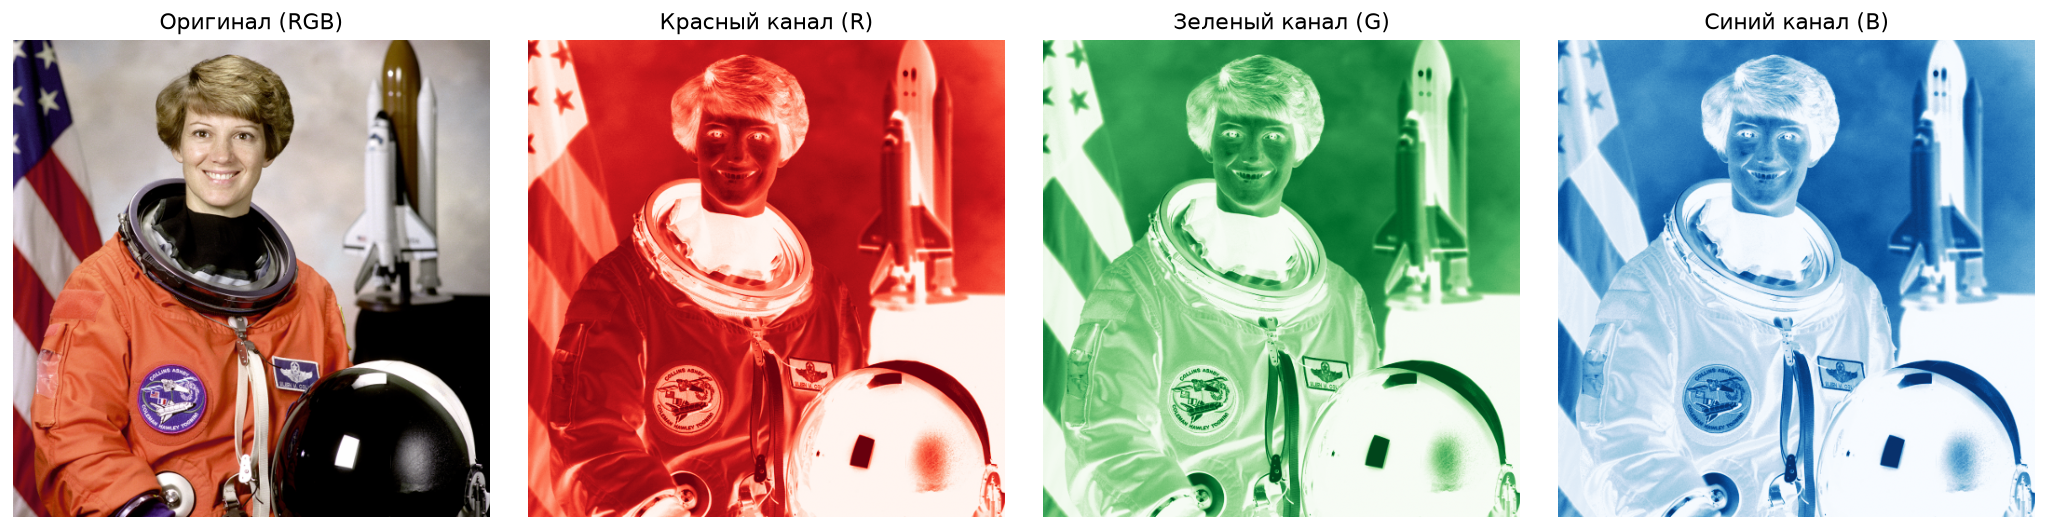

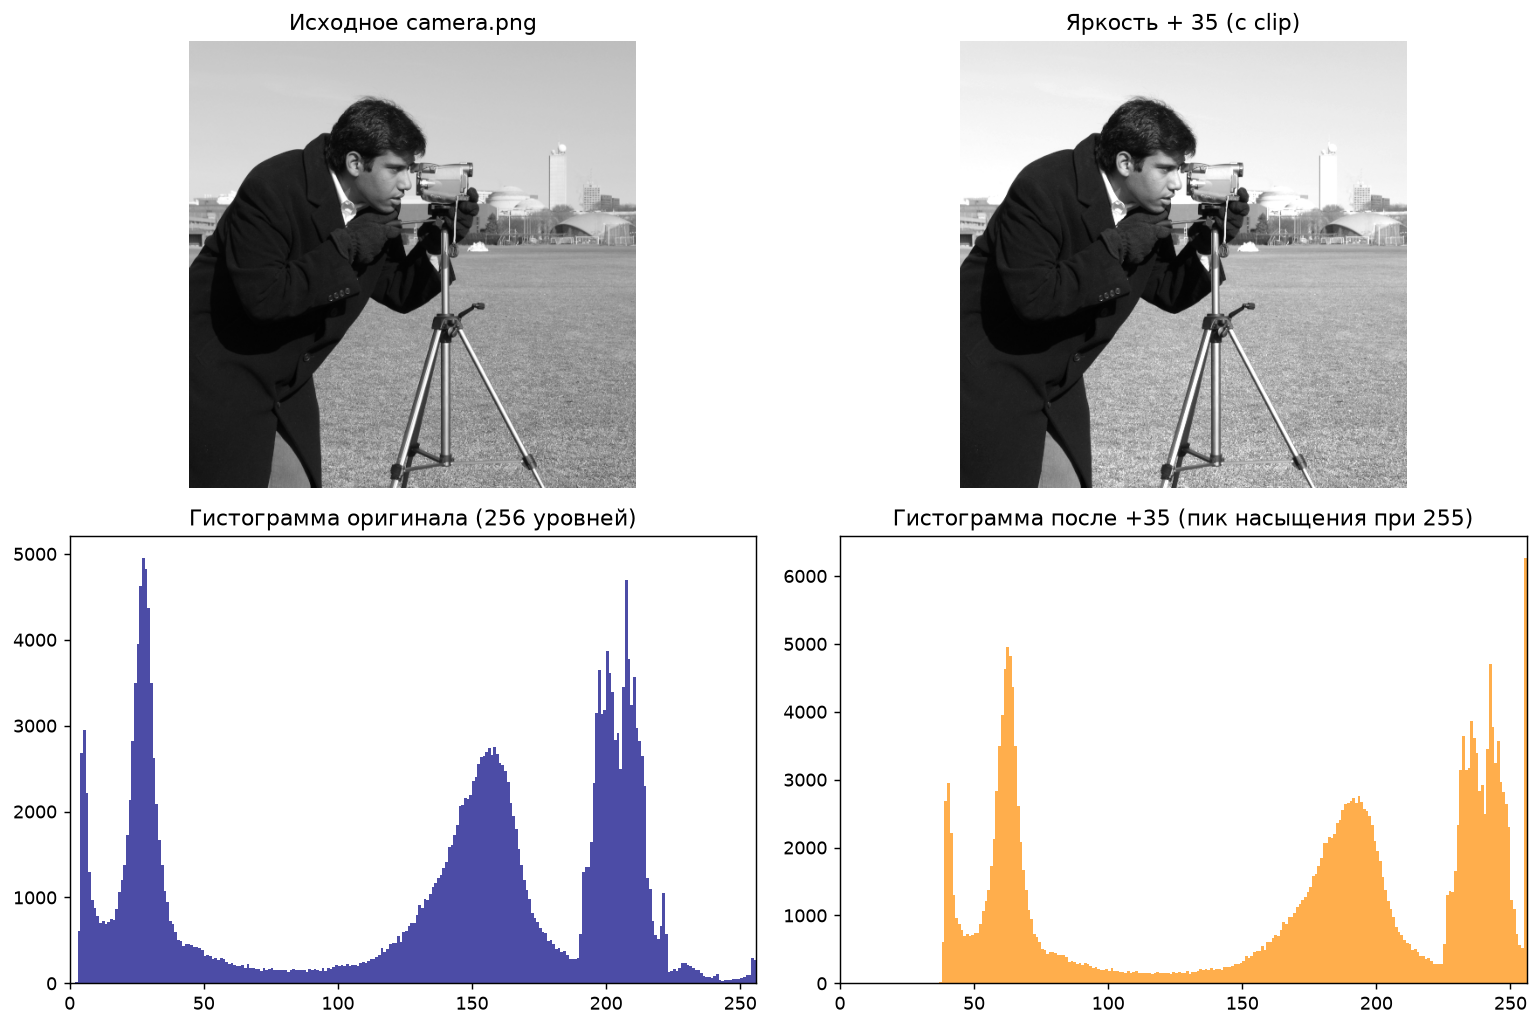

In [1]:
# Полное выполнение заданий Лабораторной работы №1
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent

# 1. Чтение camera.png в оттенках серого
cam_path = R / 'images/source/camera.png'
cam_gray = cv2.imread(str(cam_path), cv2.IMREAD_GRAYSCALE)
assert cam_gray is not None, f"Не удалось загрузить {cam_path}"
h_cam, w_cam = cam_gray.shape
pixel_val = cam_gray[70, 100] # y=70, x=100
print(f"[Задание 1] camera.png: dtype={cam_gray.dtype}, min={cam_gray.min()}, max={cam_gray.max()}, W={w_cam}, H={h_cam}")
print(f"            Значение пикселя (x=100, y=70): {pixel_val}")

# 2. astronaut.png BGR -> RGB и разделение каналов
astro_path = R / 'images/source/astronaut.png'
astro_bgr = cv2.imread(str(astro_path))
assert astro_bgr is not None, f"Не удалось загрузить {astro_path}"
astro_rgb = cv2.cvtColor(astro_bgr, cv2.COLOR_BGR2RGB)
r_ch = astro_rgb[:, :, 0]
g_ch = astro_rgb[:, :, 1]
b_ch = astro_rgb[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(astro_rgb); axes[0].set_title("Оригинал (RGB)"); axes[0].axis('off')
axes[1].imshow(r_ch, cmap='Reds'); axes[1].set_title("Красный канал (R)"); axes[1].axis('off')
axes[2].imshow(g_ch, cmap='Greens'); axes[2].set_title("Зеленый канал (G)"); axes[2].axis('off')
axes[3].imshow(b_ch, cmap='Blues'); axes[3].set_title("Синий канал (B)"); axes[3].axis('off')
plt.tight_layout()
plt.show()

# 3. Grayscale двумя способами
gray_cv = cv2.cvtColor(astro_rgb, cv2.COLOR_RGB2GRAY)
# Собственная взвешенная сумма с плавающей точкой и округлением: 0.299R + 0.587G + 0.114B
gray_custom = np.round(0.299 * r_ch.astype(float) + 0.587 * g_ch.astype(float) + 0.114 * b_ch.astype(float)).astype(np.uint8)
abs_diff = np.abs(gray_cv.astype(int) - gray_custom.astype(int))
print(f"[Задание 3] Grayscale разность (OpenCV vs формула): max diff = {np.max(abs_diff)}, mean diff = {np.mean(abs_diff):.6f}")

# 4. Гистограммы camera.png и camera.png + 35 (с насыщением)
cam_bright = np.clip(cam_gray.astype(np.int32) + 35, 0, 255).astype(np.uint8)
# Демонстрация ошибки без приведения типов (переполнение uint8):
cam_overflow = (cam_gray + np.uint8(35)) # wrap-around modulo 256

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(cam_gray, cmap='gray'); axes[0, 0].set_title("Исходное camera.png"); axes[0, 0].axis('off')
axes[0, 1].imshow(cam_bright, cmap='gray'); axes[0, 1].set_title("Яркость + 35 (с clip)"); axes[0, 1].axis('off')
axes[1, 0].hist(cam_gray.ravel(), bins=256, range=[0, 256], color='navy', alpha=0.7)
axes[1, 0].set_title("Гистограмма оригинала (256 уровней)")
axes[1, 0].set_xlim(0, 256)
axes[1, 1].hist(cam_bright.ravel(), bins=256, range=[0, 256], color='darkorange', alpha=0.7)
axes[1, 1].set_title("Гистограмма после +35 (пик насыщения при 255)")
axes[1, 1].set_xlim(0, 256)
plt.tight_layout()
plt.show()

# 5. Сравнение средней яркости и контраста: camera.png vs coffee.png
coffee_path = R / 'images/source/coffee.png'
coffee_bgr = cv2.imread(str(coffee_path))
assert coffee_bgr is not None, f"Не удалось загрузить {coffee_path}"
coffee_gray = cv2.cvtColor(coffee_bgr, cv2.COLOR_BGR2GRAY)

print(f"[Задание 5] camera.png: средняя яркость = {np.mean(cam_gray):.2f}, контраст (std) = {np.std(cam_gray):.2f}")
print(f"            coffee.png: средняя яркость = {np.mean(coffee_gray):.2f}, контраст (std) = {np.std(coffee_gray):.2f}")

# 6. Ответы на контрольные вопросы
print("""
[Контрольные вопросы]:
1) 512x512 RGB имеет 786432 компонент, так как каждый пиксель состоит из 3 независимых цветовых каналов (512 * 512 * 3 = 786432).
2) Без приведения типа сложение в uint8 происходит по модулю 256 (wrap-around arithmetic): например, 240 + 35 = 275 mod 256 = 19 (яркие пиксели внезапно становятся почти черными).
3) Saturating clip нарушает линейность, поскольку min(max(aI1 + aI2, 0), 255) != clip(aI1) + clip(aI2) при значениях, превышающих 255 (оператор отсечения неаддитивен).
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?